# Módulo 2 — Tendência e sazonalidade

## Seção 4 — Estimação da tendência por suavização e médias móveis

**Estado editorial:** seção para revisão. **Integração:** teoria, exemplos resolvidos, Python e interpretação no mesmo texto.  
**Pré-requisitos:** média, variância, independência, tendência determinística (§1), sazonalidade de período $s$ (§2) e indicadores sazonais (§3).  
**Fonte acadêmica efetivamente consultada:** MORETTIN; TOLOI, *Análise de séries temporais: modelos lineares univariados*, v. 1, 3ª ed., cap. 3, §3.2.2, pp. impressas 55–56 (páginas 74–75 do PDF disponibilizado), especialmente as equações (3.12)–(3.15). **A matemática adicional, exemplos sintéticos, código e exercícios são complementações didáticas originais.**  
**Acervo pedagógico:** `mapeamento-conteudos-series-temporais.md`, bloco C, aulas *Método das Médias Móveis: Tendência* e *Método das Médias Móveis: Sazonalidade*. O catálogo orienta a cobertura, mas não fornece os dados simulados desta seção.

### Objetivos de aprendizagem

Ao concluir esta seção, você deverá conseguir: (a) explicar a suavização como operação local; (b) escrever um filtro linear e interpretar seus pesos; (c) deduzir a preservação de tendências lineares por filtros simétricos; (d) calcular a redução de variância em condições apropriadas; (e) construir médias móveis de períodos ímpares e pares; (f) distinguir filtros **centrados** e **causais**; (g) implementar e avaliar esses cálculos em Python, sem confundir suavização retrospectiva com previsão.

### 1. Problema: ver a tendência quando os dados oscilam

Nosso modelo aditivo de trabalho é

$$
Z_t=T_t+S_t+\varepsilon_t,
$$

em que $T_t$ é tendência, $S_t$ é componente sazonal determinística e $\varepsilon_t$ representa variação aleatória. Nesta seção, investigaremos principalmente o caso em que a tendência varia lentamente em comparação às flutuações que queremos suavizar. **Suavizar** não significa demonstrar que exista uma tendência, mas construir uma estimativa local, com hipóteses e distorções controláveis.

Uma alternativa estudada na Seção 1 é ajustar uma reta ou um polinômio a **todas** as observações. A suavização, em contraste, utiliza uma vizinhança temporal para estimar o nível ao redor de cada instante. Morettin e Toloi, §3.2.2, destacam exatamente essa distinção entre ajuste global por polinômio e estimação local por observações próximas.

### 2. Definição matemática: filtros lineares

Uma classe importante de suavizadores é formada pelos **filtros lineares**, operações que substituem a observação por uma soma ponderada de observações vizinhas:

$$
\widehat T_t=\sum_{j=-m}^{m}w_j Z_{t+j},
\qquad \sum_{j=-m}^{m}w_j=1.
$$

Aqui, $m$ é o número de observações de cada lado; $2m+1$ é o comprimento da janela; $j$ é o deslocamento relativo a $t$; $w_j$ é o peso atribuído à observação $Z_{t+j}$. A soma dos pesos igual a 1 garante que uma série constante $Z_t=c$ permaneça constante após o filtro:

$$
\widehat T_t=\sum_{j=-m}^{m}w_j c
=c\sum_{j=-m}^{m}w_j=c.
$$

A condição $\sum w_j=1$ preserva constantes, mas **não** assegura, por si só, que o filtro preserve retas ou elimine sazonalidade. Para estudar essas propriedades, precisamos examinar também a distribuição dos pesos no tempo.

**Média móvel simples centrada de comprimento ímpar $2m+1$.** O caso de pesos uniformes é

$$
\boxed{\widehat T_t=\frac{1}{2m+1}\sum_{j=-m}^{m}Z_{t+j}.}
$$

Para $m=1$, isso é a média de três observações: $(Z_{t-1}+Z_t+Z_{t+1})/3$.

### 3. Exemplo manual: média móvel de três observações

Considere a sequência **determinística**, construída para verificar as contas:

$$
(z_1,z_2,z_3,z_4,z_5)=(4,7,10,13,16).
$$

O filtro centrado de três termos fornece

$$
\begin{aligned}
\widehat T_2&=(4+7+10)/3=7,\\
\widehat T_3&=(7+10+13)/3=10,\\
\widehat T_4&=(10+13+16)/3=13.
\end{aligned}
$$

Não calculamos $\widehat T_1$ nem $\widehat T_5$ com essa convenção: falta uma observação à esquerda ou à direita. **Nas bordas, não inventaremos valores.** A saída será marcada como ausente (`NaN`).

Observe que a série segue uma reta com incremento 3. A média móvel centrada preserva exatamente essa reta nas posições internas. Isso não é coincidência.

### 4. Dedução: por que um filtro simétrico preserva tendências lineares?

Suponha que a componente verdadeira seja uma função afim

$$
T_t=a+bt,
$$

e que, por enquanto, $Z_t=T_t$ (sem ruído nem sazonalidade). Aplicando um filtro linear:

$$
\begin{aligned}
\widehat T_t
&=\sum_{j=-m}^{m}w_j[a+b(t+j)]\\
&=a\sum_j w_j+bt\sum_jw_j+b\sum_jjw_j\\
&=a+bt+b\sum_jjw_j.
\end{aligned}
$$

Logo, o filtro reproduz exatamente uma tendência linear **se**

$$
\sum_jw_j=1
\quad\text{e}\quad
\sum_j j w_j=0.
$$

A segunda condição se cumpre quando os pesos são simétricos, $w_{-j}=w_j$, pois as parcelas $jw_j$ e $(-j)w_{-j}$ se cancelam. Essa é uma propriedade algébrica, não um resultado obtido pela aparência do gráfico.

**E para tendência quadrática?** Se $T_t=a+bt+ct^2$ e os pesos são simétricos e somam 1, então

$$
\widehat T_t=T_t+c\sum_jj^2w_j.
$$

Para pesos não negativos e uma janela não trivial, o termo adicional geralmente não é zero. Assim, suavização por médias móveis pode **distorcer curvaturas**, mesmo quando preserva retas.

### 5. Dedução: o que acontece com a variância do ruído?

Suponha $Z_t=T_t+\varepsilon_t$, com tendência determinística, e erros de média zero, variância $\sigma^2$ e **independentes** entre instantes. Como $T_t$ é determinística,

$$
\mathrm{Var}(\widehat T_t)
=\mathrm{Var}\!\left(\sum_jw_j\varepsilon_{t+j}\right)
=\frac{\sigma^2}{L}
$$


Para uma média uniforme de $L=2m+1$ observações, $w_j=1/L$ e

$$
\boxed{\mathrm{Var}(\widehat T_t)=\frac{\sigma^2}{L}.}
$$

A variância da componente aleatória filtrada é menor que a variância $\sigma^2$ de uma observação individual. A redução **não** significa que recuperamos a tendência verdadeira sem erro: ela ocorre sob hipóteses específicas e pode vir acompanhada de viés devido à curvatura ou à sazonalidade.

Se os erros forem correlacionados, a expressão correta passa a incluir termos cruzados:

$$
\mathrm{Var}(\widehat T_t)=\sum_j\sum_k w_jw_k
\mathrm{Cov}(\varepsilon_{t+j},\varepsilon_{t+k}).
$$

Portanto, a regra $\sigma^2/L$ não é universal em séries temporais. Além disso, janelas vizinhas compartilham dados; suas estimativas suavizadas serão, em geral, correlacionadas, mesmo com inovações independentes.

### 6. Períodos sazonais pares: por que centralizar duas vezes?

Se a série tem sazonalidade trimestral, $s=4$, uma média de quatro observações consecutivas cobre um ciclo, mas seu centro temporal está **entre** duas observações. Para alinhar o resultado com um instante inteiro, fazemos a média de duas médias móveis consecutivas de comprimento 4. O resultado é o filtro **centrado $2\times4$**:

$$
\boxed{
\widehat T_t
=\frac18 Z_{t-2}+\frac14 Z_{t-1}
+\frac14 Z_t+\frac14 Z_{t+1}+\frac18 Z_{t+2}.
}
$$

Os pesos são $\bigl(\frac18,\frac14,\frac14,\frac14,\frac18\bigr)$, somam 1 e são simétricos. Logo, preservam tendências lineares. Como usam cinco instantes, os dois primeiros e os dois últimos valores da série não terão estimativa completa.

**Por que esse filtro elimina uma sazonalidade trimestral fixa de soma zero?** Se os efeitos são $(s_1,s_2,s_3,s_4)$, repetidos a cada quatro instantes, com $\sum_{j=1}^{4}s_j=0$, então o valor sazonal do instante central reaparece nos extremos da janela ($t-2$ e $t+2$ são da mesma estação). Somados, os dois extremos contribuem $1/4$ de seu efeito; cada uma das outras três posições contribui com $1/4$ de um dos outros efeitos. Assim a contribuição sazonal total é

$$
\frac14(s_1+s_2+s_3+s_4)=0.
$$

Se o padrão mudar ao longo dos ciclos, não tiver período exatamente 4 ou existir outra sazonalidade, esse cancelamento deixará de ser exato. Este resultado depende do modelo, não garante a identificação da tendência em dados reais.

### 7. Média móvel centrada versus média causal

A média móvel **centrada** usa valores anteriores e posteriores a $t$. Para $L=2m+1$:

$$
C_t=\frac1L\sum_{j=-m}^{m}Z_{t+j}.
$$

A média móvel **causal** (ou retrospectiva) usa apenas o presente e o passado:

$$
A_t=\frac1L\sum_{j=0}^{L-1}Z_{t-j}.
$$

Para uma tendência linear $T_t=a+bt$, temos

$$
\begin{aligned}
A_t&=a+bt-\frac{b}{L}\sum_{j=0}^{L-1}j\\
&=T_t-\frac{b(L-1)}2.
\end{aligned}
$$

Portanto, em uma reta crescente ($b>0$), o filtro causal simples **fica abaixo do nível atual** porque incorpora observações passadas menores. Um filtro centrado simétrico não tem esse deslocamento para uma reta.

**Cuidado com vazamento temporal:** estimar o nível em $t$ usando $Z_{t+1}$ é legítimo em análise retrospectiva, quando todos os dados já foram observados. Não é legítimo apresentar o mesmo valor como uma estimativa disponível no instante $t$ durante um exercício de previsão em tempo real. Para modelagem preditiva, os filtros precisam respeitar a informação disponível no momento da decisão.

### 8. Python integrado — primeiro o algoritmo, depois a visualização

Dependências: **Python 3.10 ou superior**, `numpy` e `matplotlib`. O exemplo gera dados **sintéticos**, não observações meteorológicas reais. Execute o arquivo `modulo_02_secoes_04_exemplos.py` (disponibilizado com esta seção) para reproduzir as figuras e as verificações. As funções abaixo ilustram o núcleo do algoritmo, usando índices Python iniciados em zero:

In [ ]:
import numpy as np

def media_centrada_impar(valores, L):
    """Retorna uma estimativa alinhada ao centro; NaN nas bordas."""
    if L < 1 or L % 2 == 0:
        raise ValueError("L deve ser positivo e ímpar")
    resultado = np.full(len(valores), np.nan)
    m = L // 2
    for i in range(m, len(valores) - m):
        janela = valores[i-m:i+m+1]
        resultado[i] = np.mean(janela)
    return resultado

exemplo = np.array([4., 7., 10., 13., 16.])
print(media_centrada_impar(exemplo, 3))
# [nan  7. 10. 13. nan]


`np.array` converte a sequência em um vetor numérico; `np.full` preenche a saída com `NaN` (valor ausente); `//` é a divisão inteira; a fatia `a:b` inclui `a` e exclui `b`; `np.mean` calcula a média aritmética. O laço percorre apenas posições em que a janela inteira existe.

Para o período trimestral, o filtro $2\times4$ pode ser expresso diretamente pelos pesos:

In [ ]:
pesos = np.array([1, 2, 2, 2, 1]) / 8

def media_centrada_2x4(valores):
    saida = np.full(len(valores), np.nan)
    for i in range(2, len(valores) - 2):
        saida[i] = np.dot(pesos, valores[i-2:i+3])
    return saida


`np.dot` calcula o produto escalar, ou seja, multiplica cada valor pelo peso correspondente e soma as parcelas. Os índices usados no código são equivalentes à fórmula matemática do filtro.

O script complementar produz 48 observações trimestrais segundo o modelo

$$
Z_t=12+0{,}35t+S_t+\varepsilon_t,
\qquad
(S_1,S_2,S_3,S_4)=(-3,1,4,-2),
$$

com inovações normais independentes de desvio padrão $1{,}2$ e semente fixa `2026`. Ele compara uma média centrada $2\times4$ com uma média causal de comprimento 4.

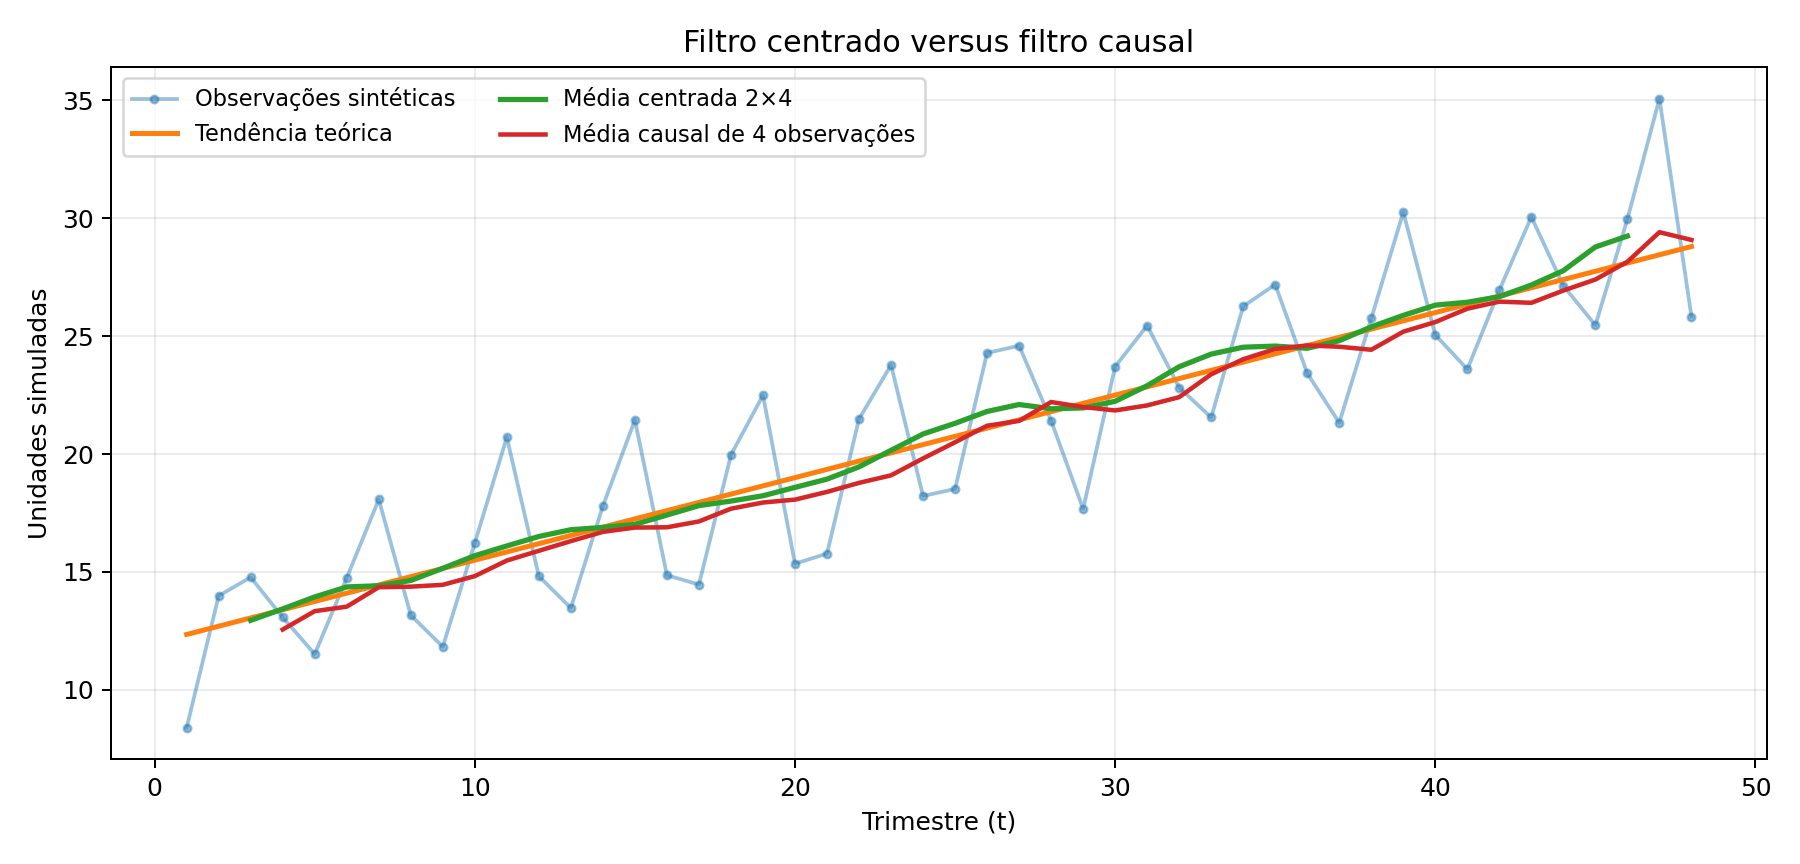

*Figura 4.1 — Série trimestral sintética, tendência conhecida e estimativas por dois filtros. A média centrada recupera melhor o alinhamento temporal da tendência linear; a média causal utiliza apenas presente e passado, mas apresenta defasagem em nível crescente. Nenhum dos métodos constitui, por si só, prova de tendência ou ferramenta automática de previsão.*

**Verificação computacional:** a execução do script confirmou que o vetor contém 48 observações, que a média $2\times4$ produz 44 posições válidas e que a média centrada de comprimento 3 retorna $7,10,13$ no exemplo manual. Esses resultados são verificações de implementação, não demonstrações probabilísticas.

### 9. Limitações e decisões metodológicas

1. **Escolha da largura:** janelas curtas suavizam pouco; longas podem esconder mudanças relevantes e picos sazonais.
2. **Bordas:** filtros centrados perdem observações nas extremidades ou exigem hipóteses de extensão da série; não preencha automaticamente usando o futuro.
3. **Sazonalidade:** uma janela incompatível com o período sazonal pode misturar tendência e sazonalidade; um filtro de comprimento apropriado não corrige padrões que variam no tempo.
4. **Dependência:** a redução de variância $\sigma^2/L$ exige erros não correlacionados com variância comum; ela não deve ser transportada para qualquer série observada.
5. **Análise retrospectiva versus previsão:** uso de dados futuros na suavização centrada é uma forma de vazamento se a estimativa for apresentada como disponível antes dessas observações.
6. **Dados ausentes:** em séries meteorológicas, ausência de registro não significa chuva zero; a janela só é comparável quando sua integridade temporal é verificada.

### 10. Exercícios graduais

**Conceitual.** Por que um filtro com pesos que somam 1 preserva uma série constante? Isso basta para preservar uma reta?

**Cálculo.** Para $z=(2,5,8,11,14,17,20)$, determine manualmente a média móvel centrada de comprimento 3 nos cinco instantes internos. Compare com a tendência linear original.

**Demonstração.** Para pesos $w_{-1}=w_1=1/4$, $w_0=1/2$, demonstre que uma função $T_t=a+bt$ é preservada e calcule o viés do filtro quando $T_t=t^2$.

**Programação guiada.** Modifique a largura da média móvel causal para 3, 4 e 6; antes de executar, escreva em pseudocódigo o cálculo e preveja onde ficarão os valores ausentes. Compare a defasagem no gráfico e justifique matematicamente o comportamento.

**Pesquisa.** Em uma série trimestral com valores faltantes, discuta por que interpolar antes da suavização pode modificar artificialmente a forma da tendência. Proponha uma análise de sensibilidade sem executar o tratamento automaticamente.

**Orientações de conferência:** no segundo exercício, os resultados internos são $5,8,11,14,17$; no terceiro, o filtro aplicado a $t^2$ resulta em $t^2+1/2$ (pois $\sum_j j^2w_j=1/2$). As demais respostas exigem justificativas, não somente números.

### 11. Síntese e referências

A média móvel é um **filtro local** cujo comportamento pode ser deduzido dos pesos. A normalização preserva constantes; a simetria preserva retas; a independência dos erros permite calcular a redução de variância; o alinhamento temporal define a legitimidade de seu uso em previsão. O próximo passo é estimar **tendência e sazonalidade simultaneamente**, evitando atribuir ao padrão sazonal movimentos causados pela tendência.

**Bibliografia acadêmica consultada:** MORETTIN, Pedro A.; TOLOI, Clélia M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed. São Paulo: Blucher, 2018. v. 1. Cap. 3, §3.2.2, pp. 55–56, eqs. (3.12)–(3.15).  
**Catálogo pedagógico consultado:** `mapeamento-conteudos-series-temporais.md`, bloco C, *Método das Médias Móveis: Tendência* e *Método das Médias Móveis: Sazonalidade*.  
**Complementações originais:** deduções de reprodução polinomial, variância do filtro, exemplo $2\times4$, comparação causal, dados simulados, código, figura e exercícios.